In [62]:
from binance.client import Client as bnb_client
from datetime import datetime
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
import get_klines

In [63]:

ticker_data = requests.get("https://api.binance.com/api/v3/ticker/24hr").json()
# Convert the API response to a DataFrame
ticker_data = pd.DataFrame(ticker_data)

# Convert volume to numeric values
ticker_data["quoteVolume"] = pd.to_numeric(
    ticker_data["quoteVolume"],
    errors="coerce"
)

top_symbols = (
    ticker_data[ticker_data["symbol"].str.endswith("USDT")]
    .sort_values("quoteVolume", ascending=False)
    .head(1000)["symbol"]
    .tolist()
)
oldest_symbols=top_symbols


In [64]:
def largest_complete_rectangle(df):
    available = df.notna().to_numpy()

    n_dates, n_stocks = available.shape

    best_area = 0
    best_start = None
    best_end = None
    best_stocks = None
    for start in range(n_dates):
        complete = np.ones(n_stocks, dtype=bool)
        for end in range(start, n_dates):
            complete &= available[end]
            stocks = np.flatnonzero(complete)
            area = (end - start + 1) * len(stocks)
            if area > best_area:
                best_area = area
                best_start = start
                best_end = end
                best_stocks = stocks.copy()
    selected_stocks = df.columns[best_stocks]
    return {
        "start_date": df.index[best_start],
        "end_date": df.index[best_end],
        "dates": df.index[best_start:best_end + 1],
        "stocks": selected_stocks,
        "n_dates": best_end - best_start + 1,
        "n_stocks": len(selected_stocks),
        "area": best_area,
    }

In [65]:
def ret_treatment(df):
    df = df.dropna(axis=0, how="all") 
    df = df.dropna(axis=1, how="all") 
    rect=largest_complete_rectangle(df)
    df = df[rect["stocks"]].loc[rect["dates"]]
    return df

In [66]:
def alpha_beta(t_interval, start_date, end_date,until):
    
    px = get_klines.find_existing_file(t_interval, start_date, end_date,until).loc[start_date:end_date]
    
    ret = ret_treatment(px.pct_change())

    ret_mean = ret.mean(axis=1).rename("mkt") 
    X = sm.add_constant(ret_mean)
    Y = ret
    results = {i:sm.OLS(Y[i], X).fit() for i in ret.columns}
    beta_contr = {i:results[i].params["mkt"]*X["mkt"]  for i in ret.columns}
    prediction = {i:results[i].params["mkt"]*X["mkt"] + results[i].params['const'] for i in ret.columns}
    alpha_contr = {i:results[i].params['const'] + results[i].resid for i in ret.columns}
    
    return ret, beta_contr, alpha_contr

def plot_beta(ret,beta_contr):
    for i in ret.columns:
        beta_contr[i].cumsum().plot() 

def plot_alpha(ret,alpha_contr):
    for i in ret.columns:
        alpha_contr[i].cumsum().plot()

In [ ]:
ret,beta,alpha=alpha_beta('1d', '2017-01-01', '2026-09-14', 1000)

Using existing data: crypto_1000_1d_2017-01-01_2026-09-14_px.pk


TypeError: find_existing_file() missing 1 required positional argument: 'x'

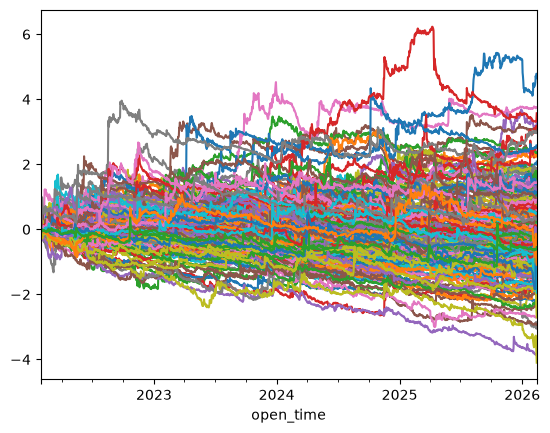

In [ ]:
plot_alpha(ret,alpha)

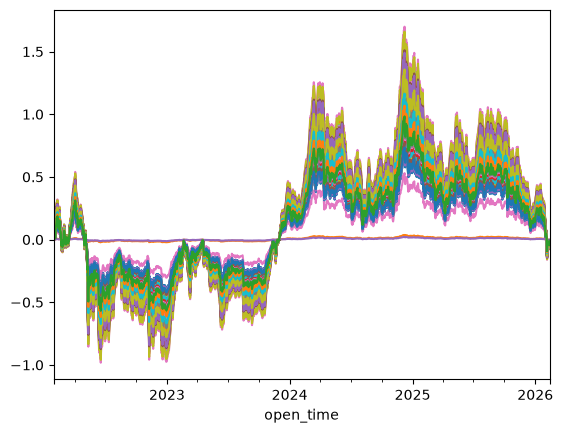

In [ ]:
plot_beta(ret,beta)

# RISK FACTORS

In [ ]:
px = pd.read_pickle("datasets/crypto_100_1d_2017-01-01_2026-09-09_px.pk")
vol = pd.read_pickle("datasets/crypto_100_1d_2017-01-01_2026-09-09_vol.pk")

In [ ]:
px,vol = get_klines.find_existing_file('30m', '2017-01-01', '2026-10-10', 1000, "vol")

Using existing data: datasets\crypto_1000_30m_2017-01-01_2026-10-10_vol.pk
Using existing data: datasets\crypto_1000_30m_2017-01-01_2026-10-10_px.pk


In [ ]:
ret = px.pct_change(fill_method=None)

## Momentum

In [ ]:
import momentum_reversal_gpu
k_max = 100
betas=momentum_reversal_gpu.main(k_max,ret)

C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


<Axes: xlabel='k'>

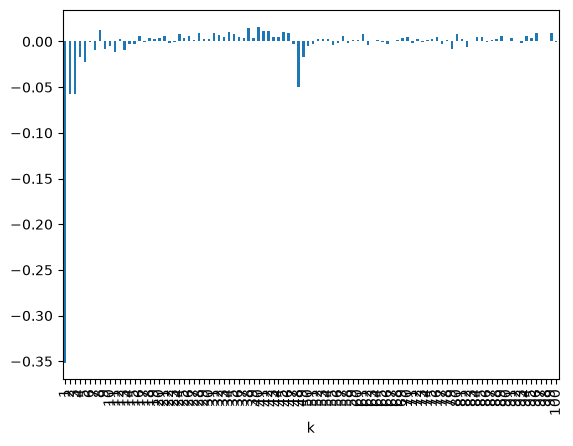

In [ ]:
gamma_k = betas["gamma"].groupby(level="k").mean()
gamma_mean = gamma_k/gamma_k.abs().sum()
gamma_mean.plot(kind='bar')

In [ ]:
p=(gamma_mean>0).replace({True: 1, False: -1})
m=-99999
for n in range(2,48):
    p_sum = p.rolling(min_periods=2,window=n).sum()
    m = p_sum.max()
    (p_sum == m).index
    n = p_sum.min()


In [ ]:
p=(gamma_mean[:46]>0).replace({True: 1, False: -1})
up=-9999
down=9999
for n in range(2,len(gamma_mean)):
    p_sum = p.rolling(min_periods=2,window=n).sum()
    p_max = p_sum.max()
    p_min = p_sum.min()
    if p_max > up:
        up=p_max
        pos=(p_sum.loc[p_sum==p_max].index[0]-n+1,p_sum.loc[p_sum==p_max].index[0])
    if p_min < down:
        down = p_min
        neg=(p_sum.loc[p_sum==p_min].index[0]-n+1,p_sum.loc[p_sum==p_min].index[0])

In [ ]:
def cumret(px, a, b):
    """Compounded return over lags a..b (inclusive), known at t-1 if a >= 1."""
    return px.shift(a) / px.shift(b + 1) - 1

In [ ]:
rev  = cumret(px, *neg)      # = px.shift(1)  / px.shift(16) - 1
mom  = cumret(px, *pos)      # = px.shift(18) / px.shift(47) - 1
size = np.log(vol.rolling(4).mean()).shift(1)

C:\Users\parra\AppData\Roaming\Python\Python312\site-packages\pandas\core\internals\blocks.py:347: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


In [ ]:
mom, rev, size = [s.reindex(index=ret.index, columns=ret.columns) for s in (mom, rev, size)]

In [ ]:
import cupy as cp
import numpy as np
import pandas as pd

q = 0.01
CH = 20000            # rows per chunk; lower to 10000 if you run out of VRAM

def gpu_qbounds(a, q):
    """Per-row q and 1-q quantiles ignoring NaN/inf (linear interpolation, like pandas)."""
    T, N = a.shape
    fin = cp.isfinite(a)
    n = fin.sum(axis=1)
    s = cp.sort(cp.where(fin, a, cp.inf), axis=1)          # non-finite values go to the end
    r = cp.arange(T)
    def pick(p):
        pos = p * cp.maximum(n - 1, 0)
        lo = cp.floor(pos).astype(cp.int64)
        hi = cp.minimum(cp.ceil(pos).astype(cp.int64), N - 1)
        f = pos - lo
        v = s[r, lo] * (1 - f) + s[r, hi] * f
        return cp.where(n > 0, v, cp.nan)
    return pick(q), pick(1 - q)

def gpu_clip(a):
    lo, hi = gpu_qbounds(a, q)
    return cp.clip(a, lo[:, None], hi[:, None])

def gpu_z(a):
    a = gpu_clip(a)
    mu = cp.nanmean(a, axis=1, keepdims=True)
    sd = cp.nanstd(a, axis=1, ddof=1, keepdims=True)
    return (a - mu) / sd

mom_n  = mom.to_numpy(dtype="float32")
rev_n  = rev.to_numpy(dtype="float32")
size_n = size.to_numpy(dtype="float32")
ret_n  = ret.to_numpy(dtype="float32")

T = len(ret)
out = np.full((T, 4), np.nan)
C = len(ret.iloc[0])

M=np.full((T,C), np.nan)
R=np.full((T,C), np.nan)
S=np.full((T,C), np.nan)


for s in range(0, T, CH):
    sl = slice(s, s + CH)
    M_s = gpu_z(cp.asarray(mom_n[sl]))
    R_s = gpu_z(cp.asarray(rev_n[sl]))
    S_s = gpu_z(cp.asarray(size_n[sl]))
    Y = gpu_clip(cp.asarray(ret_n[sl]))

    m = cp.isfinite(Y) & cp.isfinite(M_s) & cp.isfinite(R_s) & cp.isfinite(S_s)   # same as dropna()
    A = cp.stack([cp.ones_like(M_s), M_s, R_s, S_s], axis=2)                        # chunk x N x 4
    A = cp.where(m[:, :, None], A, 0)
    yv = cp.where(m, Y, 0)

    XtX = cp.matmul(A.transpose(0, 2, 1), A).astype(cp.float64)
    Xty = cp.matmul(A.transpose(0, 2, 1), yv[:, :, None]).astype(cp.float64)

    ok = m.sum(axis=1) >= 30                                  # skip warm-up / thin days
    XtX = cp.where(ok[:, None, None], XtX, cp.eye(4))         # avoid singular matrices
    beta = cp.linalg.solve(XtX, Xty)[:, :, 0]
    out[sl] = cp.asnumpy(cp.where(ok[:, None], beta, cp.nan))

    M[sl] = cp.asnumpy(M_s)
    R[sl] = cp.asnumpy(R_s)
    S[sl] = cp.asnumpy(S_s)

    cp.get_default_memory_pool().free_all_blocks()            # free VRAM between chunks

coefs = pd.DataFrame(out, index=ret.index, columns=["const", "mom", "rev", "size"]).dropna()

In [ ]:
M = pd.DataFrame(M,index=ret.index,columns=ret.columns)
R = pd.DataFrame(R,index=ret.index,columns=ret.columns)
S = pd.DataFrame(S,index=ret.index,columns=ret.columns)

In [ ]:
coefs = coefs.rename(columns={"const": "lam0"})
results = {}
for s in coefs.columns:
    reg=pd.concat({"y": coefs[s].shift(-1), "x": coefs[s]}, axis=1).dropna()
    X = sm.add_constant(reg["x"])
    ar = sm.OLS(reg["y"],X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    
    lam = coefs[s].dropna()
    mu = sm.OLS(lam.values, np.ones(len(lam))).fit(cov_type="HAC", cov_kwds={"maxlags": 48})
    results[s] = {
        "mean": np.asarray(mu.params)[0],        # average daily payoff
        "t_mean": np.asarray(mu.tvalues)[0],     # does it pay? (Fama-MacBeth test)
        "rho": ar.params["x"],                   # persistence
        "t_rho": ar.tvalues["x"],
        "R2": ar.rsquared,
        "n": int(ar.nobs),
    }

In [ ]:
results

{'lam0': {'mean': np.float64(-3.2440128085026886e-05),
  't_mean': np.float64(-2.1337006006433454),
  'rho': np.float64(-0.020039626733849816),
  't_rho': np.float64(-0.5672870409222841),
  'R2': np.float64(0.0004015850312630853),
  'n': 133292},
 'mom': {'mean': np.float64(-8.937295102006771e-06),
  't_mean': np.float64(-1.4472612022000855),
  'rho': np.float64(0.024340342457922173),
  't_rho': np.float64(1.6400329184971938),
  'R2': np.float64(0.0005924568472911451),
  'n': 133292},
 'rev': {'mean': np.float64(-0.0003745101917891775),
  't_mean': np.float64(-51.828754871203934),
  'rho': np.float64(-0.06700988546024263),
  't_rho': np.float64(-2.4290653233455206),
  'R2': np.float64(0.00449031968935687),
  'n': 133292},
 'size': {'mean': np.float64(-2.214504288692929e-05),
  't_mean': np.float64(-7.930007856817697),
  'rho': np.float64(0.009364447775807163),
  't_rho': np.float64(1.1146919666102444),
  'R2': np.float64(8.769123146856739e-05),
  'n': 133292}}

In [ ]:
def long_short(signal, ret, q=0.01):
    rank = signal.rank(axis=1, pct=True)
    return ret.where(rank >= 1 - q).mean(axis=1) - ret.where(rank <= q).mean(axis=1)

factors = pd.DataFrame({
    "MKT":  ret.mean(axis=1),
    "MOM":  long_short(mom, ret),
    "REV":  long_short(-rev, ret),
    "SIZE": long_short(-size, ret),
}).dropna()

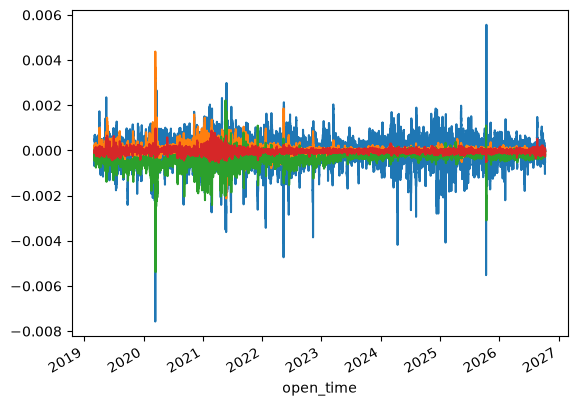

In [ ]:
#factors.to_pickle("./datasets/factors.pk")

lam_hat = coefs.rolling(window=100).mean().shift(1)
for s in ["lam0","mom","rev","size"]:
    lam_hat[s].plot()

<Axes: xlabel='open_time'>

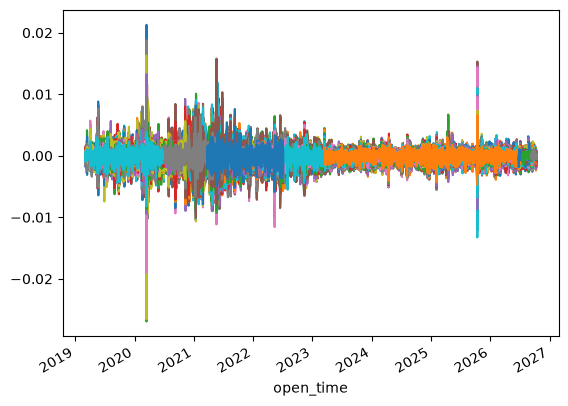

In [ ]:
prev = {i:M[i].mul(lam_hat["mom"],axis=0)+R[i].mul(lam_hat["rev"],axis=0)+S[i].mul(lam_hat["size"],axis=0)+lam_hat["lam0"] for i in ret.columns}
prev = pd.DataFrame(prev,index=ret.index,columns=ret.columns)
prev.dropna(axis=0, how="all").plot(legend=False)

In [ ]:
ret = px.pct_change(fill_method=None)

KeyboardInterrupt: 

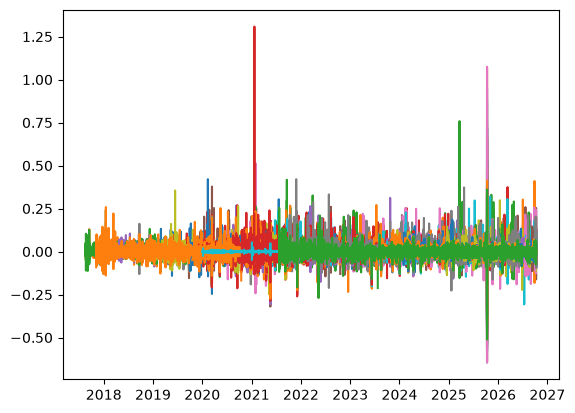

In [ ]:
ret.plot(legend=False)

KeyboardInterrupt: 

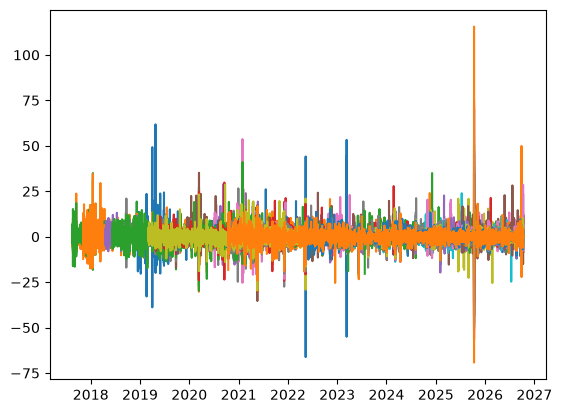

In [ ]:
((ret-ret.mean())/ret.std()).plot(legend=False)

# Trash

In [ ]:
q=0.01
def z(s):                                      
    lo, hi = s.quantile(q, axis=1), s.quantile(1-q, axis=1)
    s = s.clip(lower=lo, upper=hi, axis=0)
    return s.sub(s.mean(axis=1), axis=0).div(s.std(axis=1), axis=0)

sig = {"mom": M, "rev": R, "size": S}
y = ret.clip(lower=ret.quantile(q, axis=1), upper=ret.quantile(1-q, axis=1), axis=0)

rows = {}
for t in ret.index:
    d = pd.concat({"y": y.loc[t], **{k: v.loc[t] for k, v in sig.items()}}, axis=1).dropna()
    if len(d) < 30:                            # skip warm-up / thin days
        continue
    X = sm.add_constant(d[["mom", "rev", "size"]])
    rows[t] = sm.OLS(d["y"], X).fit().params

coefs = pd.DataFrame(rows).T                   # const, mom, rev, size

In [ ]:
ret = ret_treatment(ret)

In [ ]:
mom = (px.shift(1)-px.shift(10))/px.shift(10)
mom = ret_treatment(mom)
rev  = ret.shift(1) 
size = np.log(ret_treatment(vol).rolling(4).mean()).shift(1)
fut = ret.shift(-1)[0:len(ret)-1]

In [ ]:
def long_short(signal,q=0.3):
    rank = signal.rank(axis=1, method="first", pct=True)  #
    long = ret[rank >= 1 - q].fillna(0)
    short = ret[rank < q].fillna(0)
    return short.add(long,fill_value=0)

In [ ]:
MKT = ret.mean(axis=1),            # equal-weighted crypto market (rf ≈ 0)
MKT=np.tile(np.array(MKT)[0].reshape(len(ret.index),1), (1, len(ret.columns)))
MKT = pd.DataFrame(MKT, index=ret.index, columns=ret.columns)

MOM = long_short(mom)
#MOM = pd.DataFrame(MOM, index=ret.index, columns=ret.columns)


REV = long_short(-rev)     # long last week's losers
#REV = pd.DataFrame(REV, index=ret.index, columns=ret.columns)


SIZE = long_short(-size)     # small/illiquid minus large/liquid
#SIZE = pd.DataFrame(SIZE, index=ret.index, columns=ret.columns)

In [ ]:
rows = {}
for t in fut.index:
    df_t = pd.concat(
        {"y": fut.loc[t], "a": MKT.loc[t], "b": MOM.loc[t], "c": REV.loc[t], "d": SIZE.loc[t]},
        axis=1,
    ).dropna()
    res = sm.OLS(df_t["y"], df_t[["a", "b", "c", "d"]]).fit()
    rows[t] = res.params

coefs = pd.DataFrame(rows).T

C:\Users\parra\AppData\Local\Temp\ipykernel_2708\1657290545.py:7: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res = sm.OLS(df_t["y"], df_t[["a", "b", "c", "d"]]).fit()
C:\Users\parra\AppData\Local\Temp\ipykernel_2708\1657290545.py:7: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res = sm.OLS(df_t["y"], df_t[["a", "b", "c", "d"]]).fit()
C:\Users\parra\AppData\Local\Temp\ipykernel_2708\1657290545.py:7: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res = sm.OLS(df_t["y"], df_t[["a", "b", "c", "d"]]).fit()
C:\Users\parra\AppData\Local\Temp\ipykernel_2708\1657290545.py:7: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res = sm.OLS(df_t["y"], df_t[["a", "b", "c", "d"]]).fit()
C:\Users\parra\AppData\Local\Temp\ipykernel_2708\1657290